## Pegasus Evaluation: Load

Section B.4. Setup, methods and metrics: `2a_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.
B.4 runs on `data_source`.

In [1]:
# Data source of B.4:
# - "real": the chain of B.1 measured again under other loads and arrival patterns (statics/results_milos_v2/b4/, pegasus/real_data.py)
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
# the load- and worker-aware execution-time models of Pegasus (real data only; load_aware_b4.py next to this notebook)
from load_aware_b4 import EXTENDED, N_TRAIN, code_fingerprint, extended_training, variant_latency
b4_names = sweep_competitors + ["Oracle"]   # the methods of the tables of B.4
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/cache/evaluation/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from cache\evaluation\b1_real+b1+b1u-max4_3aea23e8588f660d.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 149 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


### B.4 Varying Load and Arrival Pattern

The chain of B.1 under other arrivals at its first service. Every method is trained as in B.1 (with real data, the
baselines of B.4a on more of their benchmark runs, see its code cell); only the arrivals and the ground truth change. Quantile Union and Conformal are retrained per setting, because they learn from
latencies monitored under load; Pegasus gets the arrival process, GP Queue the rate and $C^2$, GP Sum ignores the
arrivals. Methods as in B.1 without DNN Sum and Pegasus SNC.

**Pegasus, real data:** the load-aware execution-time models of B.1, which know the number of workers and the
load of a service (`load_aware_b4.py`). The models of the baselines are trained on benchmarks with one worker and
receive only the quality knobs; they assume that the execution time of an item depends neither on the number of
workers $c$ of its service nor on the arrival rate. On the testbed both assumptions fail for the image transformer of
this chain: it is slower with two or more workers, even for an item that runs alone, and slower at low load
(`worker_scaling_analysis.py`, `worker_scaling_coverage.py`). The models of Pegasus differ from those of the
baselines in two ways:
- *Inputs:* the GPs of the mean execution time and of the spread of single items receive the quality knobs, $c$ and
  $\log_{10}$ of the arrival rate $\lambda$ at the service (items/s). The rate stands for the load because it is known
  for every held-out run before it runs; the utilization would contain the execution time that the model predicts.
- *Training data:* every benchmark run of the service with one to four workers (`benchmark/w1/` to `benchmark/w4/`),
  the same configurations and utilizations at every $c$; no run of any chain. The one-worker benchmark alone cannot
  show the effect of $c$.

The bound is the martingale node bound of B.1, with the arrival process and the $c$ of every service in its queueing
part. With synthetic data, Pegasus uses the benchmark-trained models of B.1 like the baselines.

- **Real (`data_source = "real"`):** the chain detector → transformer → compressor with 1 to 4 workers per service,
  measured again in `statics/results_milos_v2/b4/` under every setting with the same configurations, in two
  measurements: the 50 configurations of `b1u-vision-1` and the 50 of `b1u2-vision-1`. The setting of B.1 (busiest
  service busy half of the time, Poisson arrivals) is those two chains themselves. Held-out runs (`b4_held_out` in
  `pegasus/real_data.py`): the runs in which no service has more than `b4_max_workers` workers (`MAX_WORKERS` in
  `pegasus/evaluation_setup.py`, as in every chain experiment), and that are
  valid at every setting of the sweep. The testbed marks a run as invalid when the queue of its busiest service keeps
  growing; such a run has no latency quantile at that setting, and leaving it out at every setting keeps the held-out
  configurations the same along the sweep. The ground truth is the measured latency quantile of every run, so the
  seeds change only the training draws.
- **Synthetic (`data_source = "synthetic"`):** the chain and the held-out configurations of B.1, with simulated
  arrivals and a simulated ground truth.

#### B.4a Load

Poisson arrivals at every load in `loads`. Real data: the load is the utilization $u$ of the busiest service, the share
of time that its workers are busy; the testbed sets the arrival rate of every run from a short probe so that the
busiest service reaches $u$, and the table below gives the utilization that was measured. $u = 1.0$ was measured as
well but is left out, because there the busiest service of about half of the runs was overloaded (`configure` in
`pegasus/evaluation_setup.py`). Synthetic data: the load is the arrival rate in items/s, and none of the rates
overloads a service at a held-out configuration. Figure: `figures/tsc/experimental-results/b4a_load_<data source>`.

In [2]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    # B.4a: the chain of B.1 under Poisson arrivals of different load (`loads`: arrival rate with synthetic data, utilization of the busiest service with real data)
    base_load = workload["rate"] if data_source == "synthetic" else base_utilization
    assert base_load in loads, "the load of B.1 is not one of the settings"
    # Training runs per service of the benchmark-trained models (the baselines; with synthetic data also Pegasus). Real data:
    # every benchmark run that all services have (n_pool), more than in B.1. Synthetic data: the models of B.1.
    # Real data: Pegasus trains on the worker benchmarks instead (load_aware_b4.py), so its one-worker benchmark bound is not computed.
    leave_out = only_base_case + (PROPOSED_SNC,) + ((PROPOSED,) if data_source == "real" else ())
    load_n_train = n_pool if data_source == "real" else n_train

    def compute():
        load_methods, load_truth, load_models, load_y_train = {}, {}, {}, {}   # (load, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge); seed -> models / their training data
        variant_fits = {}   # seed -> training data and load-aware models of Pegasus (variant_latency)
        # held-out configurations of every seed: synthetic, those of B.1; real, those of the first load, which every load must repeat
        held_out_x = {s: bases[s].x_test for s in seeds} if data_source == "synthetic" else {}
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for load in loads:
                for s in seeds:
                    data = b4_data(s, "load", load, n_train=load_n_train)
                    assert same_configurations(data.x_test, held_out_x.setdefault(s, data.x_test)), "the held-out configurations differ between the loads"
                    if s not in load_models:   # the execution times do not depend on the arrivals, so every load uses the same per-service models
                        load_models[s], load_y_train[s] = (base_models[s] if load_n_train == n_train else fit_services(
                            data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)), data.y_train
                    assert all(np.array_equal(data.y_train[name], load_y_train[s][name]) for name in data.path), "the training data differs between the loads"
                    load_methods[(load, s)], _ = compare_methods(data, load_models[s], data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                                 model_seed=seed + s, leave_out=leave_out, x_train_load=data.x_train_load)
                    load_truth[(load, s)] = (data.measured, data.measured_low)
                    if data_source == "real":   # Pegasus: the same held-out runs, trained on the worker benchmarks with workers and rate as inputs
                        with extended_training():
                            variant_data = b4_data(s, "load", load, training_campaign=EXTENDED, n_train=N_TRAIN)
                        assert np.array_equal(variant_data.measured, data.measured), "Pegasus holds out other runs"
                        load_methods[(load, s)] = {PROPOSED: ("proposed", variant_latency(variant_data, variant_fits, s, seed + s, alpha, confidence)),
                                                   **load_methods[(load, s)]}
        return dict(load_methods=load_methods, load_truth=load_truth, load_models=load_models, load_y_train=load_y_train)

    # the code of the load-aware models lives outside pegasus/, which the cache key does not cover otherwise
    globals().update(cached("b4a_load", data_source, compute, inputs=dict(loads=loads, load_option=load_option, load_n_train=load_n_train,
                                                                         b4_max_workers=globals().get("b4_max_workers"),
                                                                         variant=code_fingerprint() if data_source == "real" else None)))
    # utilization of the busiest service per held-out configuration: synthetic, the true one, the seeds one after the other;
    # real, the measured one of every held-out run (the same runs under every seed)
    load_utilization = {load: np.concatenate([busiest_utilization(base.path, bases[s].x_test, load, service_seed=s) for s in seeds])
                        if data_source == "synthetic" else b4_utilization("load", load, loads, b4_max_workers) for load in loads}
    if data_source == "synthetic":   # a measured run can exceed its utilization briefly; the testbed left out the runs whose queue kept growing
        assert max(utilization.max() for utilization in load_utilization.values()) < 1, "a service is overloaded at a held-out configuration"
    load_held_out = {load: len(load_truth[(load, seeds[0])][0]) for load in loads}   # held-out configurations per seed
    assert all(len(load_utilization[load]) == load_held_out[load] * (len(seeds) if data_source == "synthetic" else 1) for load in loads)
    print(f"{len(load_methods)} combinations of load and seed evaluated.")

b4a_load: results computed and saved to cache\evaluation\b4a_load_real+b1+b1u-max4_6ef32788af40f2f0.joblib


18 combinations of load and seed evaluated.


measured utilization of the busiest service, median over the held-out runs: 0.10 at u = 0.1, 0.24 at u = 0.25, 0.39 at u = 0.4, 0.49 at u = 0.5, 0.68 at u = 0.7, 0.88 at u = 0.9
B.4a load, real data: detector → transformer → compressor, 85 held-out runs (at most 4 workers per service, valid at every load),
poisson arrivals, 3 seeds


legend_inside: the legend hides 3 points or bands at its best location (upper left)


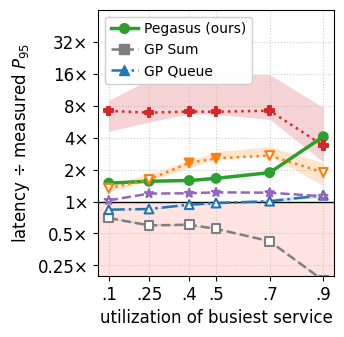

In [3]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    load_statistics = sweep_statistics(load_methods, load_truth, loads, seeds, confidence)   # name -> coverage, tightness, holds, computed
    # one short label and one row of ticks, because B.4a and B.4b sit side by side in the width of one figure; the utilization
    # of the busiest service at every rate is printed instead of drawn
    load_axis = "arrival rate λ (items/s)" if data_source == "synthetic" else "utilization of busiest service"
    if data_source == "synthetic":
        print("utilization of the busiest service, median over the held-out configurations of all seeds: "
              + ", ".join(f"{np.median(load_utilization[load]):.2f} at {load:g}/s" for load in loads))
        held_out_text = f"{load_held_out[loads[0]]} held-out configurations per seed"
    else:
        print("measured utilization of the busiest service, median over the held-out runs: "
              + ", ".join(f"{np.median(load_utilization[load]):.2f} at u = {load:g}" for load in loads))
        held_out_text = f"{load_held_out[loads[0]]} held-out runs (at most {b4_max_workers} workers per service, valid at every load)"
    tightness_sweep_figure(loads, load_statistics, load_axis,
                           f"B.4a load, {data_source} data: {' → '.join(base.path)}, {held_out_text},\n"
                           f"{workload['process']} arrivals, {len(seeds)} seeds", p_label,
                           tick_labels=[f"{load:g}".removeprefix("0") if 0 < load < 1 else f"{load:g}" for load in loads],   # .25 instead of 0.25, as in B.4b
                           log_x=False, name=f"b4a_load_{data_source}", half="left")

In [4]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    table = sweep_table(loads, load_statistics, b4_names, load_label, load_truth, seeds)
    table.loc["busiest utilization (median / max)"] = [f"{np.median(load_utilization[load]):.2f} / {load_utilization[load].max():.2f}" for load in loads]
    # an infinite bound (the model expects the busiest service to be overloaded) counts as covered, so the finite share belongs to the table
    for name in [name for name in (PROPOSED,) if name in load_statistics]:
        table.loc[f"{name}: finite share"] = [f"{finite_share(load_methods, name, load, seeds):.0%}" for load in loads]
    table.loc["held-out configurations per seed"] = [load_held_out[load] for load in loads]
    print(f"{data_source} data, tightness (median over the seeds; ● holds, ○ does not):")
    display(table)

real data, tightness (median over the seeds; ● holds, ○ does not):


,u = 0.1,u = 0.25,u = 0.4,u = 0.5,u = 0.7,u = 0.9
Pegasus (ours),1.49× ●,1.55× ●,1.58× ●,1.65× ●,1.87× ●,4.08× ●
GP Sum,0.70× ○,0.60× ○,0.60× ○,0.55× ○,0.42× ○,0.18× ○
GP Queue,0.84× ○,0.85× ○,0.93× ○,0.97× ○,1.01× ○,1.15× ○
Quantile Union,1.33× ○,1.61× ○,2.31× ●,2.55× ●,2.71× ○,1.88× ○
Conformal,7.13× ●,6.87× ●,7.04× ●,7.00× ●,7.16× ●,3.37× ●
Oracle,1.02× ○,1.19× ●,1.20× ●,1.22× ●,1.21× ●,1.12× ○
measured (s),0.0921,0.0999,0.108,0.12,0.188,0.547
busiest utilization (median / max),0.10 / 0.14,0.24 / 0.28,0.39 / 0.44,0.49 / 0.56,0.68 / 0.80,0.88 / 1.02
Pegasus (ours): finite share,100%,100%,100%,100%,100%,65%
held-out configurations per seed,85,85,85,85,85,85


#### B.4b Arrival Pattern

Renewal arrivals: the gaps between arrivals are independent and gamma-distributed, with squared coefficient of
variation $C^2$ = variance ÷ mean² of a gap, one value of `arrival_cv2s` per setting. $C^2 = 1$ is the Poisson process
of B.1, a smaller $C^2$ spaces the arrivals more evenly, and a larger one makes them burstier. $C^2 = 0$ (real data
only) is strictly periodic; the methods get it as the periodic process without jitter, because a gamma gap with
$C^2 = 0$ is degenerate (`measured_arrivals` in `pegasus/real_data.py`).

- **Real:** the busiest service of every run at utilization 0.5, as in B.1; the testbed draws gamma gaps as well. A
  setting that one of the two measurements did not complete holds out the runs of the other measurement only, so it
  has fewer held-out runs; the table gives the number per setting. The figure places the settings evenly, because
  $C^2 = 0$ has no place on a log scale.
- **Synthetic:** at the arrival rate of B.1.

Figure: `figures/tsc/experimental-results/b4b_arrivals_<data source>`.

In [5]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    # B.4b: the chain of B.1 under arrivals of different variability (`arrival_cv2s`) at the load of B.1

    # real data: Pegasus trains on the worker benchmarks (load_aware_b4.py), so its one-worker benchmark bound is not computed
    leave_out = only_base_case + (PROPOSED_SNC,) + ((PROPOSED,) if data_source == "real" else ())

    def compute():
        arrival_methods, arrival_truth = {}, {}   # (cv2, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
        variant_fits = {}   # seed -> training data and load-aware models of Pegasus (variant_latency)
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for cv2 in arrival_cv2s:
                for s in seeds:
                    data = b4_data(s, "arrivals", cv2)
                    if data_source == "synthetic":   # real data: b4_held_out checks that every setting measured the same configurations
                        assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                        assert np.array_equal(data.workload["rate"], bases[s].workload["rate"]), "the arrival rates differ from those of B.1"
                    # the execution times do not depend on the arrivals, so the per-service models of B.1 are the models of every setting
                    assert same_configurations(data.x_train, bases[s].x_train), "the training configurations differ from those of B.1"
                    assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
                    # the models of B.1 hold their beliefs at the held-out configurations of B.1; real data holds out other runs, so the
                    # same models (same training data and model seed) are fitted again to give their beliefs at the runs of B.4
                    models = base_models[s] if data_source == "synthetic" else fit_services(data, data.x_train, data.y_train, model_seed=seed + s,
                                                                                           confidence=confidence, with_dnn=False)
                    arrival_methods[(cv2, s)], _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                                   model_seed=seed + s, leave_out=leave_out, x_train_load=data.x_train_load)
                    arrival_truth[(cv2, s)] = (data.measured, data.measured_low)
                    if data_source == "real":   # Pegasus: the same held-out runs, trained on the worker benchmarks with workers and rate as inputs
                        with extended_training():
                            variant_data = b4_data(s, "arrivals", cv2, training_campaign=EXTENDED, n_train=N_TRAIN)
                        assert np.array_equal(variant_data.measured, data.measured), "Pegasus holds out other runs"
                        arrival_methods[(cv2, s)] = {PROPOSED: ("proposed", variant_latency(variant_data, variant_fits, s, seed + s, alpha, confidence)),
                                                     **arrival_methods[(cv2, s)]}
        return dict(arrival_methods=arrival_methods, arrival_truth=arrival_truth, gamma_arrivals=arrival_text(data.workload))

    # the code of the load-aware models lives outside pegasus/, which the cache key does not cover otherwise
    globals().update(cached("b4b_arrivals", data_source, compute, inputs=dict(arrival_cv2s=arrival_cv2s, b4_max_workers=globals().get("b4_max_workers"),
                                                                             variant=code_fingerprint() if data_source == "real" else None)))
    arrival_held_out = {cv2: len(arrival_truth[(cv2, seeds[0])][0]) for cv2 in arrival_cv2s}   # held-out configurations per seed
    print(f"{len(arrival_methods)} combinations of arrival variability and seed evaluated.")

b4b_arrivals: results computed and saved to cache\evaluation\b4b_arrivals_real+b1+b1u-max4_26a37dd9d379ef76.joblib
27 combinations of arrival variability and seed evaluated.


B.4b arrival variability, real data: detector → transformer → compressor, 50 to 100 held-out runs per setting (at most 4 workers per service),
renewal arrivals with gamma gaps at utilization 0.5 of the busiest service, 3 seeds
legend_inside: the legend hides 7 points or bands at its best location (upper center)


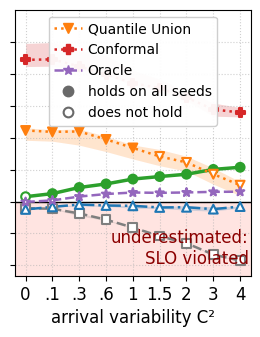

In [6]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    arrival_statistics = sweep_statistics(arrival_methods, arrival_truth, arrival_cv2s, seeds, confidence)   # name -> coverage, tightness, holds, computed
    if data_source == "synthetic":
        arrival_positions, arrival_axis, arrival_log_x = arrival_cv2s, "arrival variability C² (log scale)", True
        arrival_ticks = [f"{cv2:g}" for cv2 in arrival_cv2s]
        arrival_text_title = f"{arrival_held_out[arrival_cv2s[0]]} held-out configurations per seed,\n{gamma_arrivals}"
    else:   # C² = 0 has no place on a log scale: the settings evenly spaced, each labeled with its C²
        arrival_positions, arrival_axis, arrival_log_x = list(range(len(arrival_cv2s))), "arrival variability C²", False
        # without the leading zero (.1 instead of 0.1), so that the nine ticks fit the half-width figure
        arrival_ticks = [f"{cv2:g}".removeprefix("0") if 0 < cv2 < 1 else f"{cv2:g}" for cv2 in arrival_cv2s]
        counts = sorted(set(arrival_held_out.values()))
        arrival_text_title = (f"{' to '.join(map(str, [counts[0], counts[-1]] if len(counts) > 1 else counts))} held-out runs per setting "
                              f"(at most {b4_max_workers} workers per service),\nrenewal arrivals with gamma gaps at utilization {base_utilization:g} "
                              f"of the busiest service")
    tightness_sweep_figure(arrival_positions, arrival_statistics, arrival_axis,
                           f"B.4b arrival variability, {data_source} data: {' → '.join(base.path)}, {arrival_text_title}, {len(seeds)} seeds", p_label,
                           tick_labels=arrival_ticks, log_x=arrival_log_x, name=f"b4b_arrivals_{data_source}", half="right")

In [7]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    print(f"{data_source} data, {gamma_arrivals if data_source == 'synthetic' else 'renewal arrivals'}, tightness (median over the seeds; ● holds, ○ does not):")
    table = sweep_table(arrival_cv2s, arrival_statistics, b4_names, lambda cv2: f"C² = {cv2:g}", arrival_truth, seeds)
    for name in [name for name in (PROPOSED,) if name in arrival_statistics]:
        table.loc[f"{name}: finite share"] = [f"{finite_share(arrival_methods, name, cv2, seeds):.0%}" for cv2 in arrival_cv2s]
    table.loc["held-out configurations per seed"] = [arrival_held_out[cv2] for cv2 in arrival_cv2s]
    display(table)

real data, renewal arrivals, tightness (median over the seeds; ● holds, ○ does not):


,C² = 0,C² = 0.1,C² = 0.3,C² = 0.6,C² = 1,C² = 1.5,C² = 2,C² = 3,C² = 4
Pegasus (ours),1.11× ○,1.19× ●,1.36× ●,1.46× ●,1.63× ●,1.72× ●,1.81× ●,2.01× ●,2.10× ●
GP Sum,0.86× ○,0.85× ○,0.77× ○,0.67× ○,0.57× ○,0.47× ○,0.40× ○,0.32× ○,0.28× ○
GP Queue,0.84× ○,0.89× ○,0.94× ○,0.92× ○,0.91× ○,0.88× ○,0.88× ○,0.85× ○,0.90× ○
Quantile Union,4.67× ●,4.53× ●,4.57× ●,3.84× ●,3.20× ●,2.66× ○,2.34× ○,1.81× ○,1.43× ○
Conformal,21.57× ●,21.82× ●,18.74× ●,15.76× ●,13.01× ●,11.71× ●,9.55× ●,7.37× ●,6.89× ●
Oracle,0.99× ○,1.02× ○,1.11× ●,1.18× ●,1.22× ●,1.21× ●,1.22× ●,1.23× ●,1.24× ●
measured (s),0.0955,0.0933,0.108,0.124,0.156,0.17,0.21,0.287,0.305
Pegasus (ours): finite share,100%,100%,100%,100%,100%,100%,100%,100%,100%
held-out configurations per seed,100,100,100,100,100,100,100,100,50
